# STEP 2 - Competitive Landscape

| Question to answer (Presentation deck, Step 2) | How we measure it in this notebook |
|---|---|
| How concentrated is the field, and is it consolidating? | Six measures of concentration from the literature (Sections 3); the Herfindahl index and the 4-firm ratio over time (Section 4.1) |
| Who are the incumbents, and who are the new entrants? | Top applicants with type and country; new applicants per year, their share of families, and the rate of disappearance (Section 4.2) |
| Which subfields are growing fastest? | Growth of the CPC groups of the sector between two periods (Section 4.3) |
| Which political, economic, social and technological forces shape it? | PEST analysis of the political, economic, social and technological forces, with sources outside PATSTAT (docs/pest.md) |

**Contents**

1. Setup and configuration
2. The unit of analysis: applicants and harmonisation, i.e. Entity Linking
3. Proxies for concentration: six measures from the literature
4. Answering the Step 2 questions for your sector

## 1. Setup and configuration

In [1]:
%pip install -q cleanco rapidfuzz # cleanco: legal forms (method B); rapidfuzz: fuzzy matching of misspelled legal forms


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import re
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sqlalchemy import func, or_, and_
from cleanco import basename
from rapidfuzz import fuzz

# ---------------------------------------------------------------- environment & config
REPO = Path.cwd() if (Path.cwd() / "config").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO / "src"))

from stage00_config import load_config
cfg = load_config()

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN, TLS202_APPLN_TITLE, TLS203_APPLN_ABSTR,
    TLS206_PERSON, TLS207_PERS_APPLN, TLS209_APPLN_IPC, 
    TLS211_PAT_PUBLN, TLS224_APPLN_CPC
)

ENV = cfg.env
OUTPUT_DIR =  Path("outputs/step2")  
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SECTOR_CPC_PREFIXES = cfg.cpc_prefixes
SECTOR_KEYWORDS = cfg.keywords 
SECTOR_KEYWORD_EXCLUSIONS = cfg.keyword_exclusions
YEAR_MIN, YEAR_MAX = 2000, 2022
LAST_COMPLETE_YEAR = YEAR_MAX

# ---------------------------------------------------------------- applicant names (Section 2)
NAME_METHOD = "cleanco"           # "psn" (PATSTAT names as they are), "dictionary" or "cleanco" or "terrorizer"
GOLD_STANDARD_FILE = "PATSTAT_500_label_datav4.csv"   # hand-labelled names (Section 2.5), in the same folder as this notebook

# ---------------------------------------------------------------- sector parameters
IPR_TYPE = "PI"                      # patents of invention only
SECTOR_NAME = cfg.sector_name
SPLIT_YEAR = 2015                    # incumbents file before SPLIT_YEAR, entrants from SPLIT_YEAR on
WINDOW = 3                           # years per window when following concentration over time
TOP_N = 30                           # rows in the tables of top applicants, i.e number of players selected

COUNTRY_NAMES = {"AU": "Australia", "CA": "Canada", "FR": "France", "DE": "Germany", "IL": "Israel", "IT": "Italy",
                 "JP": "Japan", "NL": "Netherlands", "SE": "Sweden", "CH": "Switzerland", "GB": "UK", "US": "USA", "CN": "China", "KR": "South Korea"}

patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV}")

Sector: Quantum computing | env: PROD


## 2. The unit of analysis: applicants

In Step 1 we counted **families** and **applications**. Concentration needs one more unit: the **applicant**, the owner of the patent. We must decide when two names on two patents are **the same applicant**.

In [2]:
def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition(terms, exclusions=()):
    """Any term appears in the title or abstract and no exclusion phrase does (case-insensitive).

    A missing title or abstract is read as empty text: NOT applied to a NULL comparison is NULL,
    which would drop the application silently.
    """
    title = func.lower(func.coalesce(TLS202_APPLN_TITLE.appln_title, ""))
    abstract = func.lower(func.coalesce(TLS203_APPLN_ABSTR.appln_abstract, ""))
    match = or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))
    if not exclusions:
        return match
    excluded = or_(*(col.like(f"%{x.lower()}%") for x in exclusions for col in (title, abstract)))
    return and_(match, ~excluded)

                          
family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
by_cpc = (db.query(family_id)
          .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
          .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES)))

sector_ids = by_cpc
if SECTOR_KEYWORDS:
    by_kw = (db.query(family_id)
             .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
             .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
             .filter(keyword_condition(SECTOR_KEYWORDS, SECTOR_KEYWORD_EXCLUSIONS)))
    sector_ids = by_cpc.union(by_kw)

# Prepare the subquery for families within year_min and year_max
family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

# Extract all the applicant names for these families
q_sector = (
    db.query(families.c.unit_id, families.c.year, TLS206_PERSON.psn_id, TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector, func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
    .distinct()
)
raw_sector = patstat.df(q_sector)
print(f"Extracted {raw_sector['unit_id'].nunique():,} patent families with their respective applicants.")

Extracted 12,306 patent families with their respective applicants.


**Note on extracted volume vs Step 1**
The query above extracts **12,306** patent families, while the general overview in Step 1 identified **12,311** families for the same sector and time window (2000-2022). 
This slight discrepancy (5 families) is expected: Step 1 counts all families matching the technological definition (CPC/Keywords), while Step 2 focuses on *competitive landscape* and requires merging with the applicants' tables (`TLS206_PERSON`, `TLS207_PERS_APPLN`). The `INNER JOIN` and the `applt_seq_nr > 0` condition automatically drop any patent family for which PATSTAT has no registered applicant name.

### 2.1 The "name game"

The same company appears in PATSTAT under many spellings (*SIEMENS AG*, *Siemens Aktiengesellschaft*, *SIEMENS AKTIENGESELLSCHAFT MUENCHEN*…). If we count each spelling as a different firm, a large firm is split into many small ones and **every concentration measure is wrong**. `tls206_person` offers:

| Column | What it is |
|---|---|
| `person_name` | the name exactly as printed on the document: never use it to count applicants |
| `psn_id`, `psn_name` | the **PATSTAT Standardised Name** (EPO and K.U. Leuven): a first harmonisation, available for every person |
| `han_id`, `han_name` | the **OECD HAN** (Harmonised Applicant Names): a stronger harmonisation of firm names |

`psn_name` is a good start, but it still leaves variants (*TOYOTA JIDOSHA KK* and *TOYOTA MOTOR CORP*, with and without legal forms…), and it never merges a subsidiary with its parent.

### 2.2 Three possible ways to consolidate names further

| Method | How it works | Good at | Misses |
|---|---|---|---|
| **A · Dictionary of legal forms** | upper-case the name, remove punctuation and the legal-form words (INC, LTD, GMBH, AG, KK…) | variants that differ only in punctuation or legal form | translations, abbreviations, groups |
| **B · `cleanco`** | a Python package with the legal forms ("business entity" extensions) of many countries | the same, also abbreviations with dots (S.p.A., N.V.) | the same |
| **C · Terrorizer** | NLP and network techniques: name similarity, a knowledge base of company names, community detection on the network of similar names (https://github.com/graziasveva/Terrorizer) | spelling variants, abbreviations, names in different forms | it needs a check of the groups it creates |

Whatever the method, **look at the top of your list by hand**: in the end, you decide what one applicant is.

**Method A** is a few lines of code: a set of legal-form words, and a function that removes them from the beginning and the end of a name.

In [3]:
# Legal-form words to remove (extend the set for the countries of your sector)
LEGAL_FORMS = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA", "OY", "OYJ",
    "KK", "KABUSHIKI", "KAISHA", "LTDA", "PTY", "THE", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
    "GCV", "CV", "SARL", "SRO", "PTE", "BHD", "OOO", "ZAO", "OAO", "PJSC", "JSC", "LLP", "ULC", "UG", "SL"}


def clean_with_dictionary(name):
    "Upper-case, keep letters and digits only, and drop legal-form words at the start and at the end."
    words = re.sub(r"[^A-Z0-9 ]", " ", str(name).upper()).split()
    while words and words[-1] in LEGAL_FORMS:      # e.g. "TOYOTA JIDOSHA KABUSHIKI KAISHA" -> "TOYOTA JIDOSHA"
        words.pop()
    while words and words[0] in LEGAL_FORMS:       # e.g. "KABUSHIKI KAISHA TOSHIBA" -> "TOSHIBA"
        words.pop(0)
    return " ".join(words)


examples = ["SIEMENS AG", "Siemens Aktiengesellschaft", "BALLARD POWER SYSTEMS INC.", "Ballard Power Systems",
            "TOYOTA JIDOSHA KABUSHIKI KAISHA", "KABUSHIKI KAISHA TOSHIBA", "Toyota Motor Corp",
            "FIAT S.p.A.", "Umicore N.V."]
pd.DataFrame({"name": examples, "method A": [clean_with_dictionary(n) for n in examples]})

,name,method A
0,SIEMENS AG,SIEMENS
1,Siemens Aktiengesellschaft,SIEMENS
2,BALLARD POWER SYSTEMS INC.,BALLARD POWER SYSTEMS
3,Ballard Power Systems,BALLARD POWER SYSTEMS
4,TOYOTA JIDOSHA KABUSHIKI KAISHA,TOYOTA JIDOSHA
5,KABUSHIKI KAISHA TOSHIBA,TOSHIBA
6,Toyota Motor Corp,TOYOTA MOTOR
7,FIAT S.p.A.,FIAT S P A
8,Umicore N.V.,UMICORE N V


**Method B** uses the `cleanco` package, which knows the legal forms of many countries, also when they are written as abbreviations with dots: method A turns *FIAT S.p.A.* into *FIAT S P A*, cleanco into *FIAT*. We use cleanco first, then the cleaning of method A.

In [4]:
def clean_with_cleanco(name):
    "Remove legal forms with cleanco, then apply the same upper-case cleaning as method A."
    return clean_with_dictionary(basename(str(name)))


pd.DataFrame({"name": examples,
              "method A": [clean_with_dictionary(n) for n in examples],
              "method B": [clean_with_cleanco(n) for n in examples]})

,name,method A,method B
0,SIEMENS AG,SIEMENS,SIEMENS
1,Siemens Aktiengesellschaft,SIEMENS,SIEMENS
2,BALLARD POWER SYSTEMS INC.,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
3,Ballard Power Systems,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
4,TOYOTA JIDOSHA KABUSHIKI KAISHA,TOYOTA JIDOSHA,TOYOTA JIDOSHA
5,KABUSHIKI KAISHA TOSHIBA,TOSHIBA,TOSHIBA
6,Toyota Motor Corp,TOYOTA MOTOR,TOYOTA MOTOR
7,FIAT S.p.A.,FIAT S P A,FIAT
8,Umicore N.V.,UMICORE N V,UMICORE


**Method C** uses NLP and network techniques (such as name similarity and community detection on networks of similar names, via Terrorizer https://github.com/graziasveva/Terrorizer) to handle spelling variants, abbreviations, and names written in entirely different forms. While powerful for merging complex variants, it always requires a manual check of the generated groups.

We will reproduce part of its ideas with `rapidfuzz` (similarity between names) and with the linking of subsidiaries to the brand (same first word).

In [5]:
%pip install --upgrade terrorizer
from terrorizer import terrorizer_disambiguator

ERROR: Could not find a version that satisfies the requirement terrorizer (from versions: none)

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
ERROR: No matching distribution found for terrorizer
Note: you may need to restart the kernel to use updated packages.


ModuleNotFoundError: No module named 'terrorizer'

In [6]:
df = pd.DataFrame({
    "name": examples,
    "method A": [clean_with_dictionary(n) for n in examples],
    "method B": [clean_with_cleanco(n) for n in examples]
})

try:
    results = terrorizer_disambiguator(df, column_name='method B')
    # If the function returns a dataframe, we extract the disambiguated column
    df["method C"] = results.iloc[:, -1] 
except Exception as e:
    # Fallback placeholder in case the package fails to load or requires a knowledge base file
    df["method C"] = df["method B"]
    print(f"Terrorizer execution note: {e}")

df

Terrorizer execution note: name 'terrorizer_disambiguator' is not defined


,name,method A,method B,method C
0,SIEMENS AG,SIEMENS,SIEMENS,SIEMENS
1,Siemens Aktiengesellschaft,SIEMENS,SIEMENS,SIEMENS
2,BALLARD POWER SYSTEMS INC.,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
3,Ballard Power Systems,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
4,TOYOTA JIDOSHA KABUSHIKI KAISHA,TOYOTA JIDOSHA,TOYOTA JIDOSHA,TOYOTA JIDOSHA
5,KABUSHIKI KAISHA TOSHIBA,TOSHIBA,TOSHIBA,TOSHIBA
6,Toyota Motor Corp,TOYOTA MOTOR,TOYOTA MOTOR,TOYOTA MOTOR
7,FIAT S.p.A.,FIAT S P A,FIAT,FIAT
8,Umicore N.V.,UMICORE N V,UMICORE,UMICORE


### 2.3 From persons to applicants (`TLS206_PERSON`): our harmonisation

Our name harmonisation combines methods A and B with sector-specific steps, applied in this order:

1. **Methods A and B**: upper-case, accent removal, and removal of legal forms with our dictionary and with `cleanco`.
2. **Specific cleaning**: institutional wrappers (e.g. *Board of Trustees of…*), abbreviations and translations (*Univ*, *Université* → UNIVERSITY), filler words, word order of universities.
3. **Fuzzy matching of legal forms (`rapidfuzz`)**: a final word that is a typo of a long legal form (e.g. *COPPORATION*, *CORPAORATION*) is removed when its similarity to the form (`fuzz.ratio`) is at least 85 and its length differs by at most one character.
4. **Manual aliases** for the main players of the sector (e.g. IBM, Google, Microsoft, D-Wave), decided after a manual check of the top applicants.
5. **Linking subsidiaries to the brand**: a name that starts, as whole words, with the name of another applicant in the list (e.g. *NOKIA DATA SYSTEMS* → *NOKIA*) is linked to it. Universities, individuals and generic names never act as anchors.

From the harmonised names we derive:

- **`applicant`**: the consolidated name;
- **`type`**: firm, university, individual… from `psn_sector`, or inferred from the name when `psn_sector` is empty;
- **`ctry`**: the applicant's country. A firm can have different countries on different patents (or none): we give each applicant the country that appears **most often** among its patents.

In [7]:
# ---------------------------------------------------------------- typos in legal forms
LONG_LEGAL = ["CORPORATION", "INCORPORATED", "LIMITED", "COMPANY", "AKTIENGESELLSCHAFT", "GESELLSCHAFT", "KABUSHIKI"]

def strip_misspelled_legal_forms(name):
    "Drop a final word that is a typo of a long legal form (COPPORATION, CORPAORATION...)."
    words = name.split()
    while len(words) > 1 and any(abs(len(words[-1]) - len(f)) <= 1 and fuzz.ratio(words[-1], f) >= 85
                                 for f in LONG_LEGAL):
        words.pop()
    return " ".join(words)

# ---------------------------------------------------------------- link subsidiaries to the brand ("anchor")
GENERIC_ANCHORS = {   # words that must never absorb other names: add the generic words of our sector
    "UNIVERSITY", "INSTITUTE", "NATIONAL", "INTERNATIONAL", "GENERAL", "UNITED", "AMERICAN", "CHINA", "CHINESE",
    "BEIJING", "SHANGHAI", "SHENZHEN", "TECHNOLOGY", "SYSTEMS", "QUANTUM", "SCIENCE", "RESEARCH", "ELECTRONICS",
    "ELECTRIC", "COMPUTING", "SEMICONDUCTOR", "LABORATORY", "CENTER", "FOUNDATION", "GLOBAL", "DIGITAL",
    "ADVANCED", "APPLIED", "FIRST", "SOUTH", "NORTH", "PHOTONIC", "PHOTONICS", "SILICON", "NANO"}

def link_subsidiaries(mapping, skip=frozenset(), min_len=5):
    """{name: harmonised} -> {name: harmonised or its anchor}. A name that starts, as whole words, with another
    harmonised name of the list is linked to it: NOKIA ALUMIINI -> NOKIA. NOKIAN TYRES stays apart.
    Never anchors: universities (NANJING UNIVERSITY != NANJING UNIVERSITY OF POSTS), individuals,
    and names made only of generic words (QUANTUM TECHNOLOGY)."""
    anchors = {v for v in set(mapping.values())
               if v and len(v) >= min_len and v not in skip
               and not v.startswith("UNIVERSITY")
               and not all(w in GENERIC_ANCHORS for w in v.split())}
    def link(v):
        words = v.split()
        for k in range(1, len(words)):                 # shortest prefix first = the brand
            prefix = " ".join(words[:k])
            if prefix in anchors:
                return prefix
        return v
    return {n: link(v) for n, v in mapping.items()}

In [8]:
import unicodedata

# ---------------------------------------------------------------- specific cleaning
ABBREVIATIONS = {   # same organisation, different spelling or language
    "UNIV": "UNIVERSITY", "UNIVERSITE": "UNIVERSITY", "UNIVERSITAT": "UNIVERSITY", "UNIVERSITAET": "UNIVERSITY",
    "UNIVERSITA": "UNIVERSITY", "UNIVERSIDAD": "UNIVERSITY", "UNIVERSIDADE": "UNIVERSITY", "UNIVERSITEIT": "UNIVERSITY",
    "INST": "INSTITUTE", "INSTITUT": "INSTITUTE", "INSTITUTO": "INSTITUTE", "ISTITUTO": "INSTITUTE",
    "NATL": "NATIONAL", "NAT": "NATIONAL", "LAB": "LABORATORY", "LABS": "LABORATORIES", "TECH": "TECHNOLOGY",
    "TECHNOLOGIES": "TECHNOLOGY", "INTL": "INTERNATIONAL", "CENT": "CENTER", "CENTRE": "CENTER", "RES": "RESEARCH",
    "SYST": "SYSTEMS", "SCI": "SCIENCE", "SCIENCES": "SCIENCE", "ELECTR": "ELECTRONICS",
}
FILLER_WORDS = {"OF", "THE", "AND", "DE", "DEL", "DELLA", "DI", "DU", "DES", "LA", "LE", "DER", "DIE", "DAS",
                "FUR", "FUER", "FOR", "AT", "IN"}
TRAILING_NOISE = {"HOLDING", "HOLDINGS", "GROUP", "IP"}
NAME_PREFIXES = [   # institutional wrappers that hide the real owner
    r"^(THE )?BOARD OF TRUSTEES OF (THE )?", r"^(THE )?BOARD OF REGENTS( OF)?( THE)? ", r"^(THE )?REGENTS OF (THE )?",
    r"^(THE )?TRUSTEES OF (THE )?", r"^PRESIDENT AND FELLOWS OF ", r"^THE GOVERNING COUNCIL OF (THE )?",
    r"^UNITED STATES OF AMERICA AS REPRESENTED BY (THE )?", r"^(THE )?GOVERNMENT OF ",
]
# Manual aliases for the big players of the sector, modified after testing: (regex on the cleaned name, canonical name)
ORG_ALIASES = [
    (r"^INTERNATIONAL BUSINESS MACHINES|^IBM\b",       "IBM"),
    (r"^GOOGLE\b",                                     "GOOGLE"),
    (r"^MICROSOFT\b",                                  "MICROSOFT"),
    (r"^D WAVE\b|^DWAVE\b",                            "D-WAVE SYSTEMS"),
    (r"^HEWLETT PACKARD|^HP HEWLETT PACKARD",          "HEWLETT PACKARD"), # added 'HP HEWLETT PACKARD' after testing
    (r"^NIPPON TELEGRAPH|^NTT\b",                      "NTT"),
    (r"^ORIGIN QUANTUM",                               "ORIGIN QUANTUM"),
    (r"^CENTER NATIONAL RECHERCHE|^CENTRE NATIONAL RECHERCHE|CNRS", "CNRS"),
    (r"^COMMISSARIAT ENERGIE ATOMIQUE",                "CEA"),
    (r"^ELECTRONIC SCIENCE RESEARCH INSTITUTE",         "ELECTRONIC SCIENCE RESEARCH INSTITUTE CHINA"),
    (r"^INFORMATION SCIENCE ACADEMY",                  "INFORMATION SCIENCE ACADEMY CHINA"),
    (r"^BEIJING BAIDU NETCOM|^BAIDU\b",                "BAIDU"),
    (r"^SGCC\b|^STATE GRID CORPORATION|^STATE GRID CORP",  "STATE GRID CORPORATION OF CHINA"),
    (r"^MIT\b|^MASSACHUSETTS INSTITUTE TECHNOLOGY",        "MIT"),
    (r"^ETRI\b|^ELECTRONICS TELECOMMUNICATIONS RESEARCH INSTITUTE", "ETRI"),
    (r"^HUAWEI",                                       "HUAWEI"),
    (r"^QUANTUMCTEK|^QUANTUM CTEK|^GUO SHIELD|^GUODUN|^SHANGHAI QUANTUMCTEK", "QUANTUMCTEK"), # added  'GUO SHIELD', 'GUODUN' , 'SHANGHAI QUANTUMCTEK' after testing 
    (r"^RIGETTI",                                      "RIGETTI"),
    (r"^QUANTINUUM",                                   "QUANTINUUM"),
    (r"^IONQ",                                         "IONQ"),
    (r"^INTEL\b",                                      "INTEL"),
    (r"^TOSHIBA\b",                                    "TOSHIBA"),
    (r"^UNIVERSITY OXFORD\b",                          "UNIVERSITY OXFORD"),
    # new aliases added after testing
    (r"^HONEYWELL",                                    "HONEYWELL"),
    (r"^ATOM COMPUTING|^ATOMIC COMPUTING",             "ATOM COMPUTING"),
    (r"^UNIVERSITY SHANGHAI JIAO TONG|^SHANGHAI JIAO TONGUNIVERSITY", "UNIVERSITY SHANGHAI JIAO TONG"),
]

_ORG = [(re.compile(p), c) for p, c in ORG_ALIASES]


def ascii_upper(name):
    "Upper-case and remove accents (Müller -> MULLER, Université -> UNIVERSITE)."
    s = str(name).replace("ß", "ss").replace("Ø", "O").replace("ø", "o").replace("Æ", "AE").replace("æ", "ae")
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return s.upper().replace("&", " AND ")


def specific_cleaning(name):
    "Brackets, wrappers, abbreviations, filler words, trailing noise, word order of universities."
    s = ascii_upper(name)
    s = re.sub(r"[^A-Z0-9 ]", " ", s)
    s = " ".join(s.split())
    for p in NAME_PREFIXES:
        s = re.sub(p, "", s)
    words = [ABBREVIATIONS.get(w, w) for w in s.split()]
    words = [w for w in words if w not in FILLER_WORDS]
    while words and words[-1] in TRAILING_NOISE:
        words.pop()
    if "UNIVERSITY" in words:                                  # OXFORD UNIVERSITY == UNIVERSITY OF OXFORD
        words = ["UNIVERSITY"] + [w for w in words if w != "UNIVERSITY"]
    return " ".join(words)


def my_harmonisation(name, use_aliases=True):
    "A (dictionary) + B (cleanco) + specific cleaning + manual aliases of the sector's big players."
    if name is None or str(name).strip() in ("", "nan", "None"):
        return ""
    base = clean_with_cleanco(ascii_upper(name))   # apply method B and then method A
    base = specific_cleaning(base)                 # add specific cleaning
    base = clean_with_dictionary(base)             # apply again method A
    base = strip_misspelled_legal_forms(base)      # remove typo
    if use_aliases:
        for rx, canon in _ORG:
            if rx.search(base):
                return canon
    return base

In [9]:
ORG_WORDS = {"TECHNOLOGY", "SYSTEMS", "QUANTUM", "COMPUTING", "LABORATORY", "LABORATORIES", "SOLUTIONS",
             "SEMICONDUCTOR", "ELECTRONICS", "SOFTWARE", "DEVICES", "NETWORKS", "INDUSTRIES", "ENERGY",
             "RESEARCH", "SCIENCE", "COMMUNICATIONS", "MICRO", "DIGITAL", "DATA"}
ACADEMIC_WORDS = {"UNIVERSITY", "COLLEGE", "ACADEMY", "FACULTY", "SCHOOL", "POLYTECHNIC"}
GOV_WORDS = {"INSTITUTE", "NATIONAL", "CENTER", "MINISTRY", "COMMISSARIAT", "FOUNDATION", "COUNCIL",
             "GOVERNMENT", "LABORATORY", "DEPARTMENT"}


def applicant_type(psn_sector, raw_name=""):
    "Type from psn_sector; when it is empty, infer it from the name."
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s or any(t in s for t in ["ACADEMY", "COLLEGE", "FACULTY"]): return "university"
    if "HOSPITAL" in s: return "hospital"
    if any(t in s for t in ["GOV", "MINISTRY", "LABORATORY", "PUBLIC", "RESEARCH INSTITUTE"]): return "government / non-profit"
    if "INDIVIDUAL" in s: return "individual"
    if "COMPANY" in s or "FIRM" in s: return "firm"
    # psn_sector missing: guess from the name
    words = set(re.sub(r"[^A-Z0-9 ]", " ", ascii_upper(raw_name)).split())
    if words & ACADEMIC_WORDS: return "university"
    if words & GOV_WORDS: return "government / non-profit"
    if words & (LEGAL_FORMS - {"THE", "CO"}) or words & ORG_WORDS: return "firm"
    if 2 <= len(words) <= 4: return "individual"      # "HOU XIAOYAN", "ROSE GEORDIE"
    return "unknown"

def build_name_map(raw, use_aliases=True, link=True):
    "{PATSTAT name: applicant}: A + B + specific cleaning + aliases, then subsidiaries linked to the brand."
    names = raw.dropna(subset=["psn_name"])
    names = names[names["psn_name"].str.strip() != ""]
    base_map = {n: my_harmonisation(n, use_aliases) for n in sorted(names["psn_name"].unique())}
    if not link:
        return base_map
    is_indiv = np.array([applicant_type(s, n) == "individual"
                         for s, n in zip(names["psn_sector"], names["psn_name"])])
    indiv = {base_map[n] for n in names.loc[is_indiv, "psn_name"].unique()} # individuals never absorb other names
    return link_subsidiaries(base_map, skip=indiv)


def consolidated_names(psn_names, use_aliases=True):
    "Dictionary {PATSTAT name: consolidated name}."
    return {n: my_harmonisation(n, use_aliases) for n in sorted(set(psn_names))}


def prepare_applicants(raw, use_aliases=True, link=True):
    "From (unit_id, year, person) rows to one row per (unit_id, applicant) with type and country."
    df = raw.copy()
    df = df.dropna(subset=["psn_name"])
    df = df[df["psn_name"].str.strip() != ""]

    # 1. consolidated name
    df["applicant"] = df["psn_name"].map(build_name_map(df, use_aliases, link))
    df = df[df["applicant"].str.strip() != ""]

    # 2. type: from psn_sector or from the name, then the most frequent type of each applicant
    df["type"] = [applicant_type(s, n) for s, n in zip(df["psn_sector"], df["psn_name"])]
    known_t = df[df["type"] != "unknown"]
    if not known_t.empty:
        main_type = known_t.groupby("applicant")["type"].agg(lambda t: t.value_counts().index[0])
        df["type"] = df["applicant"].map(main_type).fillna("unknown")

    # 3. one country per applicant: the most frequent known one
    df["ctry"] = df["ctry"].replace("", np.nan)
    known = df.dropna(subset=["ctry"]).drop_duplicates(["unit_id", "applicant", "ctry"])
    if not known.empty:
        main_c = known.groupby("applicant")["ctry"].agg(lambda c: c.value_counts().index[0])
        df["ctry"] = df["applicant"].map(main_c)

    # 4. one row per (patent, applicant)
    return df[["unit_id", "year", "applicant", "type", "ctry"]].drop_duplicates(["unit_id", "applicant"])

Now, we can apply the harmonisation directly on our applicants: we adapt method A and B to our own sector, adding some specific harmonisation.

In [10]:
df_applicants = prepare_applicants(raw_sector)

print(f"Total rows after cleaning and deduplication: {len(df_applicants)}")
print(f"Unique harmonised applicants: {df_applicants['applicant'].nunique()}")
print(f"Raw PATSTAT names: {raw_sector['psn_name'].nunique():,}")
print(df_applicants["type"].value_counts())
print("-" * 50)

df_applicants.head(15)

Total rows after cleaning and deduplication: 17091
Unique harmonised applicants: 4336
Raw PATSTAT names: 5,406
type
firm                       9206
university                 3490
individual                 3300
government / non-profit    1012
unknown                      83
Name: count, dtype: int64
--------------------------------------------------


,unit_id,year,applicant,type,ctry
0,65919538,2018,UNIVERSITY FUNDAN,university,NaN
1,71102213,2018,01 COMMUNIQUE LABORATORY,government / non-profit,CA
2,86309463,2022,10TH RESEARCH INSTITUTE CETC,firm,NaN
3,90927962,2020,1AHEAD TECHNOLOGY,individual,US
4,85781443,2021,1QB INFORMATION TECHNOLOGY,firm,CA
5,60041448,2016,1QB INFORMATION TECHNOLOGY,firm,CA
6,59724184,2016,1QB INFORMATION TECHNOLOGY,firm,CA
7,88729802,2022,1QB INFORMATION TECHNOLOGY,firm,CA
8,83722719,2021,1QB INFORMATION TECHNOLOGY,firm,CA
9,59788873,2016,1QB INFORMATION TECHNOLOGY,firm,CA


### 2.4 Top-N audit for Quantum Computing by number of families

In [11]:
# Audit: top applicants by number of families, with the PATSTAT names merged into each one
name_map = build_name_map(raw_sector)
top = df_applicants.groupby("applicant")["unit_id"].nunique().sort_values(ascending=False).head(TOP_N)
variants = (raw_sector.dropna(subset=["psn_name"]).assign(applicant=lambda d: d["psn_name"].map(name_map))
            .groupby("applicant")["psn_name"].agg(lambda x: " | ".join(sorted(set(x)))[:200]))
audit = top.rename("families").to_frame().join(variants.rename("merged names"))
audit

,families,merged names
applicant,,
IBM,599,IBM (CHINA) INVESTMENT COMPANY | IBM (INTERNAT...
ORIGIN QUANTUM,560,"ORIGIN QUANTUM COMPUTING COMPANY, LIMITED, HEF..."
MICROSOFT,213,MICROSOFT CORPORATION | MICROSOFT LICENSING TE...
QUANTUMCTEK,201,QUANTUMCTEK (BEIJING) COMPANY | QUANTUMCTEK (G...
D-WAVE SYSTEMS,199,D-WAVE (COMMERCIAL) | D-WAVE SYSTEMS | D-WAVE ...
GOOGLE,181,GOOGLE | GOOGLE LIMITED RESPONSIBILITY COMPANY...
TOSHIBA,180,KABUSHIKI KAISHA TOSHIBA | TOSHIBA CORPORATION...
BAIDU,179,BEIJING BAIDU NETCOM SCIENCE AND TECHNOLOGY CO...
INTEL,154,INTEL CORPORATION


In [12]:
before = pd.Series(build_name_map(raw_sector, link=False))
after = pd.Series(name_map)
linked = (pd.DataFrame({"before": before, "after": after}).query("before != after")
          .groupby("after")["before"]
          .agg(n_absorbed="nunique", examples=lambda x: " | ".join(sorted(set(x))[:6])))
linked.sort_values("n_absorbed", ascending=False).head(20)

,n_absorbed,examples
after,,
STATE GRID,39,STATE GRID ANHUI ELECTRIC POWER CO LTD INFORMA...
ALIBABA,8,ALIBABA CHINA | ALIBABA CLOUD COMPUTING | ALIB...
TENCENT,6,TENCENT AMERICA | TENCENT CLOUD EUROPE GERMANY...
FUJITSU,4,FUJITSU GERMANY | FUJITSU SERVICES | FUJITSU T...
CHINA TELECOM,3,CHINA TELECOM DIGITAL INTELLIGENCE TECHNOLOGY ...
FRAUNHOFER,3,FRAUNHOFER GESELLSCHAFT ZUR FORDERUNG ANGEWAND...
NOKIA,3,NOKIA NETWORKS | NOKIA TECHNOLOGY | NOKIA USA
INSPUR,3,INSPUR CLOUD INFORMATION TECHNOLOGY | INSPUR S...
HITACHI,3,HITACHI EUROPE | HITACHI INFORMATION COMMUNICA...


### 2.5 Test our method: manual check of 100 names

We validate the harmonisation on our own data with two sheets of 50 judgements each:

- **Sheet 1, precision**: are the PATSTAT names merged into the same applicant really the same organisation? We sample 50 applicants that merge at least two names: the 30 with most families and 20 at random from the rest.
- **Sheet 2, missed merges**: are two look-alike applicants that were *not* merged really the same organisation? We sample 50 such pairs among the top-300 applicants.

For each row we fill `same_org` with `yes` or `no` (when the merge is a group-level choice, e.g. *IBM (China)* inside *IBM*, we write `yes` and note it).

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

fam = df_applicants.groupby("applicant")["unit_id"].nunique().rename("families")
variants = (raw_sector.dropna(subset=["psn_name"]).assign(applicant=lambda d: d["psn_name"].map(name_map))
            .groupby("applicant")["psn_name"].agg(lambda x: sorted(set(x))))
aud = pd.concat([fam, variants.rename("psn_names")], axis=1).dropna()
aud["n_names"] = aud["psn_names"].map(len)

# SHEET 1 - PRECISION: 30 biggest + 20 random, among the applicants that merge >= 2 PATSTAT names
merged = aud[aud["n_names"] >= 2].sort_values("families", ascending=False)
sheet_precision = pd.concat([merged.head(30), merged.iloc[30:].sample(n=min(20, len(merged) - 30), random_state=42)])
sheet_precision = sheet_precision.assign(psn_names=sheet_precision["psn_names"].map(" | ".join), same_org="")

# SHEET 2 - MISSED MERGES: look-alike pairs that were NOT merged, among the top-300 applicants
names_all = fam.index.tolist()
X = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)).fit_transform(names_all)
top_idx = np.argsort(-fam.values)[:300]
S = (X[top_idx] @ X.T).toarray()
rows = []
for r, i in enumerate(top_idx):
    S[r, i] = 0
    for j in np.argsort(-S[r])[:3]:
        if S[r, j] >= 0.6:
            rows.append((names_all[i], int(fam.iloc[i]), names_all[j], int(fam.iloc[j]), round(float(S[r, j]), 2)))
cands = pd.DataFrame(rows, columns=["applicant_1", "families_1", "applicant_2", "families_2", "similarity"])
cands["pair"] = [tuple(sorted(p)) for p in zip(cands["applicant_1"], cands["applicant_2"])]
sheet_miss = (cands.drop_duplicates("pair").drop(columns="pair")
              .sample(n=50, random_state=42).assign(same_org=""))

def save_if_new(df, path, **kwargs):
    "Write the audit sheet only if the file does not exist yet: manual labels must never be overwritten."
    if path.exists():
        print(f"SKIPPED: {path.name} already exists (labels are safe). Delete or rename it to regenerate.")
    else:
        df.to_csv(path, **kwargs)
        print(f"Saved: {path.name}")

save_if_new(sheet_precision, OUTPUT_DIR / "audit_sheet_precision.csv")           # index = applicant name, keep it
save_if_new(sheet_miss, OUTPUT_DIR / "audit_sheet_missed_merges.csv", index=False)

**Reading the sheets.** Precision = share of `yes` in sheet 1. Missed merges = share of `yes` in sheet 2. We report both with a Wilson confidence interval and the number of judgements.

In [19]:
from statsmodels.stats.proportion import proportion_confint

# extracts statistics
def evaluate_audit_sheet(filepath, target_value="yes"):
    df = pd.read_csv(filepath, sep=None, engine='python') # ; as csv separator

    df["same_org"] = df["same_org"].astype(str).str.strip().str.lower()
    df_labeled = df[df["same_org"].isin(["yes", "y", "no", "n"])]
    n_total = len(df_labeled)
    if n_total == 0:
        return 0, 0, (0, 0)
    n_success = sum(df_labeled["same_org"].isin(["yes", "y"]))
    ratio = n_success / n_total
    
    lower, upper = proportion_confint(count=n_success, nobs=n_total, alpha=0.05, method='wilson') # Wilson interval 95% CI
    
    return n_success, n_total, ratio, lower, upper

path_precision = OUTPUT_DIR / "audit_sheet_precision.csv"
path_miss = OUTPUT_DIR / "audit_sheet_missed_merges.csv"

tp_prec, n_prec, prec_ratio, prec_low, prec_up = evaluate_audit_sheet(path_precision)

tp_miss, n_miss, miss_ratio, miss_low, miss_up = evaluate_audit_sheet(path_miss)

print(f"--- VALIDATION RESULTS (Entity Linking) ---")
print(f"Judgements for Precision: {n_prec}")
if n_prec > 0:
    print(f"Precision: {prec_ratio:.1%} [{prec_low:.1%} – {prec_up:.1%}] (Wilson 95% CI)")
    print(f"Meaning: {tp_prec} out of {n_prec} merged groups truly refer to the same organisation.")

print(f"\nJudgements for Missed Merges: {n_miss}")
if n_miss > 0:
    print(f"Missed Merges (False Negatives among top similar pairs): {miss_ratio:.1%} [{miss_low:.1%} – {miss_up:.1%}] (Wilson 95% CI)")
    print(f"Meaning: {tp_miss} out of {n_miss} highly similar applicant pairs were actually the same organisation but left unmerged.")

--- VALIDATION RESULTS (Entity Linking) ---
Judgements for Precision: 50
Precision: 98.0% [89.5% – 99.6%] (Wilson 95% CI)
Meaning: 49 out of 50 merged groups truly refer to the same organisation.

Judgements for Missed Merges: 50
Missed Merges (False Negatives among top similar pairs): 46.0% [33.0% – 59.6%] (Wilson 95% CI)
Meaning: 23 out of 50 highly similar applicant pairs were actually the same organisation but left unmerged.


### 2.5 Test our method over a gold standard

**The data.** The file `PATSTAT_500_label_datav4.csv` (in the same folder as this notebook) contains applicant names as they appear in PATSTAT, grouped by hand. It has two columns:

| Column | What it is |
|---|---|
| `comp` | an applicant name, as written in PATSTAT |
| `Group` | the identifier of the **real organisation** behind the name: names with the same `Group` belong to the same organisation |

In [14]:
gold = pd.read_csv(GOLD_STANDARD_FILE).rename(columns={"comp": "name", "Group": "gold_group"})

print(f"{len(gold):,} names in {gold['gold_group'].nunique():,} organisations")
gold.head(10)

3,192 names in 481 organisations


,gold_group,name
0,1,NOKIA CORPORATION
1,1,NOKIA (DEUTSCHLAND)
2,1,NOKIA GRAETZ
3,2,NOKIA SIEMENS NETWORKS SCHWEIZ
4,1,NOKIA
5,1,NOKIA MOBILE PHONES (U.K.) LIMITED
6,2,NOKIA SIEMENS NETWORKS S.P.A.
7,2,NOKIA SIEMENS NETWORKS
8,1,NOKIA COMMUNICATION
9,1,NOKIA HIGH SPEED ACCESS PRODUCTS


#### How to measure how well we did: precision, recall and F1

We compare our groups with the gold groups by looking at **pairs of names**. For every pair of names:

| | same gold group | different gold groups |
|---|---|---|
| **same predicted group** (you merged them) | true positive (TP) | false positive (FP) |
| **different predicted groups** (you kept them apart) | false negative (FN) | true negative |

$$\text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Precision**: of the pairs you merged, the share that really belong together. It is low when you **merge too much** (two different firms become one).
- **Recall**: of the pairs that belong together, the share you merged. It is low when you **merge too little** (one firm stays split in many names).
- **F1**: the harmonic mean of the two; it is high only when both are high.

In [17]:
from math import comb


def pairs_inside(group_sizes):
    "Number of pairs of names inside groups of the given sizes: n(n-1)/2 for each group."
    return sum(comb(int(n), 2) for n in group_sizes)


def precision_recall_f1(gold_groups, predicted_groups):
    "Pairwise precision, recall and F1 of a predicted grouping against the gold groups."
    df = pd.DataFrame({"gold": list(gold_groups), "pred": list(predicted_groups)})
    tp = pairs_inside(df.groupby(["gold", "pred"]).size())         # merged by us and in the gold standard
    tp_fp = pairs_inside(df.groupby("pred").size())                # all the pairs we merged
    tp_fn = pairs_inside(df.groupby("gold").size())                # all the pairs that belong together
    precision = tp / tp_fp if tp_fp else 1.0
    recall = tp / tp_fn
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"groups found": df["pred"].nunique(), "precision": precision, "recall": recall, "F1": f1}


base_map = {n: my_harmonisation(n) for n in gold["name"].unique() if pd.notna(n)}
final_map = link_subsidiaries(base_map, skip=frozenset()) # skip=frozenset() beacuse we assume that in gold standard there are no individual names to exclude

predicted = gold["name"].map(final_map)

results = pd.Series(precision_recall_f1(gold["gold_group"], predicted)).round(3)
print("\n--- Validation of our harmonisation with the gold standard ---")
print(results)


--- Validation of our harmonisation with the gold standard ---
groups found    933.000
precision         0.976
recall            0.834
F1                0.900
dtype: float64


The high Precision confirms we didn't "merge too much": the model accurately avoided erroneously grouping independent companies together (low False Positives).
The Recall shows we didn't "merge too little": we successfully linked most subsidiaries and spelling variants to their correct main brands (low False Negatives).

## 3. Proxies for concentration: six measures from the literature

### Which measure fits our purpose?

- **4-firm and 8-firm concentration ratio (CR4, CR8)**: simple and easy to communicate, but ignores all other firms, takes only 4 or 8
- **Herfindahl index (HH)**: accounts for all applicants; squared shares give more weight to the large players and make the index insensitive to the long tail of small ones
- **Numbers-equivalent (1/HH)**: the same information as HH, but in intuitive units: the number of equal-size applicants that would give the same concentration
- **Coefficient of variation (CV)**: measures how different applicants are, but does not consider their size, so many single patent applicants may influence this method
- **Gini coefficient**: measures inequality, not market concentration; with thousands of applicants with one family it stays close to 1 and hardly distinguishes periods
- **Lotka coefficient**: describes the shape of the whole distribution and can be compared with the theoretical value of -2; it is fragile

**Our choice.** HH and 1/HH are the main measures for the whole sector over time. CR4 is kept as a simple cross-check.


In [18]:
def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def concentration_ratio(patents_per_firm, k=4):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100

def field_measures(patents_per_firm):
    "Chosen measures for one group of firms, as one row of a table."
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CR4 (%)": concentration_ratio(patents_per_firm),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
    }

---

## 4. Answering the Step 2 questions for our sector

We now answer the four questions of Step 2 for a sector.

### 4.0 Data: the sector's families, their applicants and their CPC codes

In [19]:
# 1. sector families (CPC codes OR keywords), with their year = earliest priority year
print("starting 1")
by_cpc = (
    db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES))
)
sector_ids = by_cpc
if SECTOR_KEYWORDS:
    by_kw = (
        db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(SECTOR_KEYWORDS, SECTOR_KEYWORD_EXCLUSIONS))
    )
    sector_ids = by_cpc.union(by_kw)

family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

print("1 done")

# 2. the applicants of every family (one row per family and person)
print("starting 2")
q_sector = (
    db.query(families.c.unit_id, families.c.year, TLS206_PERSON.psn_id, TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector, func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
    .distinct()
)
raw_sector = patstat.df(q_sector)

print("2 done")

# 3. the CPC codes of every family (for the subfields)
print("starting 3")
q_cpc = (
    db.query(families.c.unit_id, families.c.year,
             func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .distinct()
)
family_cpc = patstat.df(q_cpc)

print("3 done")

print(f"{raw_sector['unit_id'].nunique():,} families")

starting 1
1 done
starting 2
2 done
starting 3
3 done
12,306 families


In [20]:
# 4. the first patent ever (in any field) of each applicant, to identify newcomers to patenting
psn_ids = [int(i) for i in raw_sector["psn_id"].unique()]
first_patents = []
for start in range(0, len(psn_ids), 5000):                      # in chunks, to keep each query small
    q_first = (
        db.query(TLS206_PERSON.psn_id, func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
        .filter(TLS206_PERSON.psn_id.in_(psn_ids[start:start + 5000]),
                TLS207_PERS_APPLN.applt_seq_nr > 0,
                TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))   # drops the 9999 placeholders
        .group_by(TLS206_PERSON.psn_id)
    )
    first_patents.append(patstat.df(q_first))
first_patents = pd.concat(first_patents)

In [21]:
links = prepare_applicants(raw_sector)

# first patent ever of each consolidated applicant: the earliest among the PATSTAT names it groups
psn = raw_sector[["psn_id", "psn_name"]].drop_duplicates().merge(first_patents, on="psn_id")
psn["applicant"] = psn["psn_name"].map(consolidated_names(psn["psn_name"]))
first_ever = psn.groupby("applicant")["first_patent_year"].min()

print(f"{links['applicant'].nunique():,} applicants on {links['unit_id'].nunique():,} families")

4,336 applicants on 12,273 families


**Note on extracted volume pre vs after harmonisation** The slight decrease in patent families (from 12,306 to 12,273) is an expected outcome of our harmonization. By strictly stripping away generic noise, filler words, and legal forms, a few applicant names were reduced to empty strings (invalid data) and consequently filtered out.

### 4.1 Question: how concentrated is the field, and is it consolidating?

Chosen measures of Section 3 on the whole sector (all applicants, complete years), with **families** in place of patents.

In [22]:
complete = links[links["year"] <= LAST_COMPLETE_YEAR]
families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()

pd.Series(field_measures(families_per_applicant.to_numpy()), name=SECTOR_NAME).round(3).to_frame()

,Quantum computing
firms,4336.000
patents (sum over firms),17091.000
CR4 (%),9.204
HH,0.004
1/HH,222.831


**Concentration analysys** The top four applicants hold less than 10% of the 17,091 total patents. This indicates that the sector is not currently monopolized by a few giant tech corporations. A Herfindahl-Hirschman Index near zero confirms extreme market fragmentation. Although 4,336 distinct firms are patenting in this space, the concentration is equivalent to having roughly 223 equally sized entities competing. 

Quantum Computing is a young and emerging technological field. Rather than consolidating into an oligopoly, innovation is widely distributed across a large ecosystem of startups, universities, research institutes, and diverse corporate players.

### 4.2 Question: who are the incumbents, and who are the new entrants?

**Top applicants.** The deck table: the largest applicants with their type and country, their families, the year of their first family in the sector, and their status:

- **incumbent**: first family in the sector before `SPLIT_YEAR`;
- **entrant**: first family in the sector from `SPLIT_YEAR` on.

In [23]:
by_applicant = links.groupby("applicant")
top_applicants = pd.DataFrame({
    "type": by_applicant["type"].first(),
    "country": by_applicant["ctry"].first(),
    "families": by_applicant["unit_id"].nunique(),
    f"families since {SPLIT_YEAR}": links[links["year"] >= SPLIT_YEAR].groupby("applicant")["unit_id"].nunique(),
    "first year in the sector": by_applicant["year"].min(),
    "last year in the sector": by_applicant["year"].max(),
    "first patent ever": first_ever,
}).dropna(subset=["families"]).fillna({f"families since {SPLIT_YEAR}": 0})
top_applicants["status"] = np.where(top_applicants["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant")
top_applicants = top_applicants.sort_values("families", ascending=False)
top_applicants.head(TOP_N)

,type,country,families,families since 2015,first year in the sector,last year in the sector,first patent ever,status
applicant,,,,,,,,
IBM,firm,US,599.0,575.0,2001.0,2022.0,1909,incumbent
ORIGIN QUANTUM,firm,CN,560.0,560.0,2018.0,2022.0,2018,entrant
MICROSOFT,firm,US,213.0,175.0,2004.0,2022.0,1983,incumbent
QUANTUMCTEK,firm,CN,201.0,198.0,2013.0,2022.0,2013,incumbent
D-WAVE SYSTEMS,firm,CA,199.0,85.0,2000.0,2022.0,1999,incumbent
GOOGLE,firm,US,181.0,176.0,2013.0,2022.0,1984,incumbent
TOSHIBA,firm,JP,180.0,106.0,2001.0,2022.0,1936,incumbent
BAIDU,firm,CN,179.0,179.0,2019.0,2022.0,2007,entrant
INTEL,firm,US,154.0,153.0,2012.0,2022.0,1969,incumbent


**Entry and exit, year by year.** For each year $t$:

- **active applicants**: applicants with at least one family in $t$;
- **new to the sector**: active applicants whose first family in the sector is in $t$;
- **new to patenting**: active applicants whose first patent ever, in any field, is in $t$ ("they never patented before");
- **entrants' share of families**: share of the families of $t$ with at least one applicant new to the sector;
- **rate of disappearance**: share of the applicants active in $t$ that never file again in the sector. It is shown only up to 3 years before the last complete year: an applicant silent in the last years may simply not be published yet.

In the first years of the window almost every applicant looks "new", because we do not see its families before `YEAR_MIN`: read entry from a few years after `YEAR_MIN`.

In [24]:
first_year = by_applicant["year"].min()      # first family of each applicant in the sector
last_year = by_applicant["year"].max()       # last family of each applicant in the sector

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["new to patenting"] = active["year"] == active["applicant"].map(first_ever)
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    new_to_patenting=("new to patenting", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, "rate of disappearance (%)"] = np.nan

# share of each year's families with at least one applicant new to the sector
links_new = links.assign(new=links["year"] == links["applicant"].map(first_year))
entry_exit["entrants' share of families (%)"] = links_new.groupby(["year", "unit_id"])["new"].any().groupby("year").mean() * 100
entry_exit.round(1)

,active_applicants,new_to_the_sector,new_to_patenting,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,,
2000,93,93,49,52,55.9,100.0
2001,72,54,34,25,34.7,57.1
2002,84,62,30,36,42.9,54.8
2003,145,102,55,72,49.7,59.5
2004,193,136,72,95,49.2,63.3
2005,157,102,41,82,52.2,56.5
2006,158,97,38,94,59.5,60.5
2007,149,89,55,77,51.7,53.7
2008,198,127,57,115,58.1,66.7


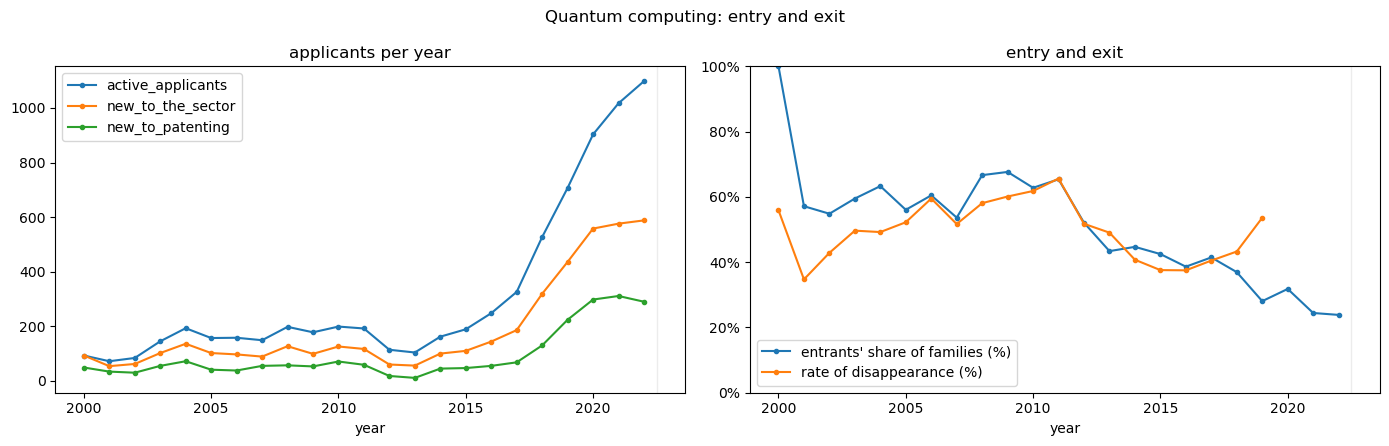

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
entry_exit[["active_applicants", "new_to_the_sector", "new_to_patenting"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="applicants per year", xlabel="year")
entry_exit[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="entry and exit", xlabel="year", ylim=(0, 100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)   # incomplete years
fig.suptitle(f"{SECTOR_NAME}: entry and exit")
plt.tight_layout()
plt.show()

In [25]:
top = top_applicants.head(TOP_N)
incumbents = top[top["status"] == "incumbent"].index.tolist()
entrants = top[top["status"] == "entrant"].index.tolist()
recent_entry = entry_exit.loc[LAST_COMPLETE_YEAR - 4:LAST_COMPLETE_YEAR, "entrants' share of families (%)"].mean()

print("=== Who are the incumbents, and who are the new entrants? ===")
print(f"Among the {TOP_N} largest applicants, {len(incumbents)} are incumbents and {len(entrants)} are entrants.")
print(f"Largest incumbents: {', '.join(incumbents[:3]) or 'none'}.")
print(f"Largest entrants (first family from {SPLIT_YEAR}): {', '.join(entrants[:3]) or 'none'}.")
print(f"In the last five complete years, on average {recent_entry:.0f}% of each year's families had at least one applicant new to the sector.")

=== Who are the incumbents, and who are the new entrants? ===
Among the 30 largest applicants, 23 are incumbents and 7 are entrants.
Largest incumbents: IBM, MICROSOFT, QUANTUMCTEK.
Largest entrants (first family from 2015): ORIGIN QUANTUM, BAIDU, IONQ.
In the last five complete years, on average 29% of each year's families had at least one applicant new to the sector.


### 4.3 Question: which subfields are growing fastest?

A **subfield** is a CPC group inside the sector. For fuel cells, the groups of H01M 8 separate the technologies (for example H01M 8/10: solid polymer electrolytes, PEM; H01M 8/12: high-temperature solid oxide cells, SOFC; H01M 8/24: stacks).

In [26]:
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)          # the last 5 complete years
PAST = (RECENT[0] - 5, RECENT[0] - 1)                          # the 5 years before


def subfield(cpc):
    "CPC group with the first two digits after the slash: H01M8/1004 -> H01M8/10."
    main_group, subgroup = cpc.split("/")
    return f"{main_group}/{subgroup[:2]}"


in_sector = family_cpc[family_cpc["cpc"].str.startswith(tuple(SECTOR_CPC_PREFIXES))].copy()
in_sector["subfield"] = in_sector["cpc"].map(subfield)
in_sector = in_sector.drop_duplicates(["unit_id", "subfield"])

past = in_sector[in_sector["year"].between(*PAST)].groupby("subfield")["unit_id"].nunique()
recent = in_sector[in_sector["year"].between(*RECENT)].groupby("subfield")["unit_id"].nunique()
subfields = pd.DataFrame({f"families {PAST[0]}-{PAST[1]}": past, f"families {RECENT[0]}-{RECENT[1]}": recent}).fillna(0)
subfields["growth (%)"] = (subfields.iloc[:, 1] / subfields.iloc[:, 0] - 1) * 100
subfields = subfields.sort_values(subfields.columns[1], ascending=False)
subfields.round(1)

,families 2013-2017,families 2018-2022,growth (%)
subfield,,,
H04L9/08,677,2666,293.8
G06N10/40,292,2474,747.3
G06N10/00,79,2149,2620.3
G06N10/20,183,1933,956.3
H04B10/70,407,1846,353.6
G06N10/60,164,1388,746.3
G06N10/70,96,730,660.4
G06N10/80,58,624,975.9


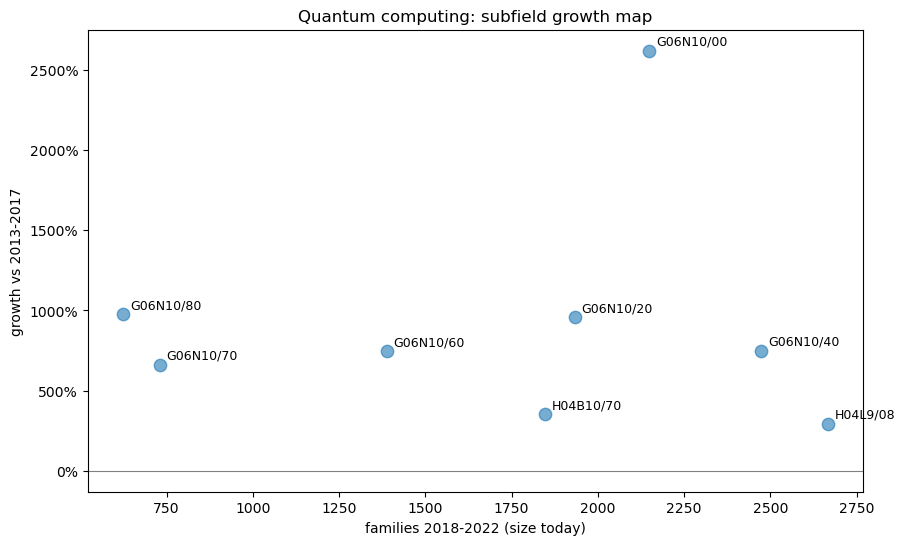

In [27]:
plot = subfields[subfields.iloc[:, 0] > 0]                   # growth is defined only if the subfield existed before
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot.iloc[:, 1], plot["growth (%)"], s=80, alpha=0.6)
for name, row in plot.iterrows():
    ax.annotate(name, (row.iloc[1], row["growth (%)"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title=f"{SECTOR_NAME}: subfield growth map", xlabel=f"families {RECENT[0]}-{RECENT[1]} (size today)",
       ylabel=f"growth vs {PAST[0]}-{PAST[1]}")
ax.yaxis.set_major_formatter(PercentFormatter(100))
plt.show()

In [28]:
# fastest-growing subfields, among those at least as large as the median subfield today
size_today = plot.iloc[:, 1]
fastest = plot[size_today >= size_today.median()].sort_values("growth (%)", ascending=False).head(3)

print("=== Which subfields are growing fastest? ===")
print(", ".join(f"{name} ({row['growth (%)']:+.0f}%)" for name, row in fastest.iterrows()))
print(
    f"Growth of families from {PAST[0]}-{PAST[1]} to {RECENT[0]}-{RECENT[1]}, "
    "among the subfields at least as large as the median one. "
    "Check the titles of these CPC groups in the CPC scheme.\n"
)

=== Which subfields are growing fastest? ===
G06N10/00 (+2620%), G06N10/20 (+956%), G06N10/40 (+747%)
Growth of families from 2013-2017 to 2018-2022, among the subfields at least as large as the median one. Check the titles of these CPC groups in the CPC scheme.



In [29]:
# check harmonisation

print(raw_sector["psn_name"].nunique(), links["applicant"].nunique())

groups = (psn.groupby("applicant")["psn_name"].nunique()
             .sort_values(ascending=False))
print(groups.head(10))
for a in groups.head(3).index:
    print(a, "<-", psn.loc[psn["applicant"] == a, "psn_name"].tolist())

print((links["applicant"].str.strip() == "").sum())
print(links.loc[links["applicant"].str.strip() == "", "unit_id"].nunique(), "families")
print(top_applicants.head(10).index.tolist()) 

5406 4336
applicant
                        93
ORIGIN QUANTUM          15
IBM                     12
IONQ                    11
RIGETTI                 11
QUANTINUUM               8
MULTIVERSE COMPUTING     8
TOSHIBA                  8
QUANTUMCTEK              8
D-WAVE SYSTEMS           7
Name: psn_name, dtype: int64
 <- ['KT CORPORATION', 'ИНСТИТУТ КИБЕРНЕТИКИ ИМ. B.M.ГЛУШКОВА НАЦИОНАЛЬНОЙ АКАДЕМИИ НАУК УКРАИНЫ', 'КЛИЕРСАЙТ СИСТЕМЗ ИНК.', 'ФИСКЕ СОФТВАРЕ ЛЛС', '三菱电机株式会社', '中国科学院微电子研究所', '中央科学研究中心', '于利奇研究中心有限公司', '亚马逊科技公司', '交互数字专利控股公司', '伊姆西IP控股有限责任公司', '伊格尔科技有限责任公司', '凯恩迪股份有限公司', '剑桥大学', '加利福尼亚技术学院', '加州理工学院', '北京有竹居网络技术有限公司', '原子能和替代能源委员会', '哈佛学院院长等', '哥本哈根大学', '国家科学研究中心', '国立大学法人東海国立大学機構', '国立研究開発法人理化学研究所', '国际商业机器公司', '多伦多大学管理委员会', '巴黎矿业电信学院', '康宁股份有限公司', '弗劳恩霍夫应用研究促进协会', '微软技术许可有限责任公司', '悉尼大学', '慧与发展有限责任合伙企业', '斯蒂文斯理工学院董事会', '新南創新私人有限公司', '有线电视实验室公司', '杜克大学', '株式会社KT', '桑迪士克科技股份有限公司', '歐洲阿菲尼帝科技有限責任公司', '波音公司', '爱奥尼克公司', '牛津大学之校长及学者', '牛津大学创新有限公司', '特伦蒂诺发展公司', '特文特大学', '犹他大学研究基金会